# 2. Exploratory data analysis and preprocessing

Run notebook 1 first. Use development data only for EDA and fitted preprocessing.


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OneHotEncoder, StandardScaler


### Setup

In [2]:
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'data/processed/cohort.csv').exists():
    raise FileNotFoundError('Run notebook 1 from the project folder first.')

SEED = json.loads((ROOT / 'config.json').read_text())['seed']
OUT = ROOT / 'notebooks' / 'outputs'
for folder in ['figures', 'tables']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
plt.rcParams.update({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
BLUE, ORANGE = '#246b83', '#c26b32'


## Data: use the development partition

Load development encounters. Remove identifiers, outcomes, and split metadata from the predictors.


In [3]:
cohort = pd.read_csv(
    ROOT / 'data/processed/cohort.csv',
    keep_default_na=False, na_values=['?'], low_memory=False,
)
assert cohort.groupby('patient_nbr')['split'].nunique().eq(1).all()
dev = cohort[cohort['split'] == 'development'].reset_index(drop=True)


### Choose predictors

In [4]:
excluded_columns = [
    'encounter_id', 'patient_nbr', 'readmitted',
    'target', 'split', 'partition_fold',
]
X = dev.drop(columns=excluded_columns)
y = dev['target']


### Identify numerical features

In [5]:
numeric_features = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses',
]
numeric_data = X[numeric_features]


### Inspect development data

In [6]:
print(f'{len(dev):,} development encounters, {dev.patient_nbr.nunique():,} patients')
print(
    f'{X.shape[1]} candidate predictors: '
    f'{len(numeric_features)} numerical and '
    f'{X.shape[1] - len(numeric_features)} categorical'
)
preview_features = [
    'age', 'time_in_hospital', 'number_inpatient',
    'A1Cresult', 'medical_specialty',
]
display(X[preview_features].head())


59,670 development encounters, 41,960 patients
47 candidate predictors: 8 numerical and 39 categorical


,age,time_in_hospital,number_inpatient,A1Cresult,medical_specialty
0,[0-10),1,0,None,Pediatrics-Endocrinology
1,[10-20),3,0,None,NaN
2,[30-40),2,0,None,NaN
3,[40-50),1,0,None,NaN
4,[70-80),5,0,None,NaN


## Results: class balance and missing values

Check the class proportions and missing values.


In [7]:
class_counts = y.value_counts().reindex([0, 1], fill_value=0)
missing_count = X.isna().sum()
missingness = pd.DataFrame({
    'missing_count': missing_count,
    'missing_percent': missing_count / len(X) * 100,
}).sort_values('missing_percent', ascending=False)
missingness.index.name = 'feature'
missing_features = missingness[missingness['missing_count'] > 0]
display(missing_features.round(2))


,missing_count,missing_percent
feature,,
weight,57765,96.81
medical_specialty,29215,48.96
payer_code,23626,39.59
race,1344,2.25
diag_3,831,1.39
diag_2,212,0.36
diag_1,15,0.03


### Plot class balance and missing values

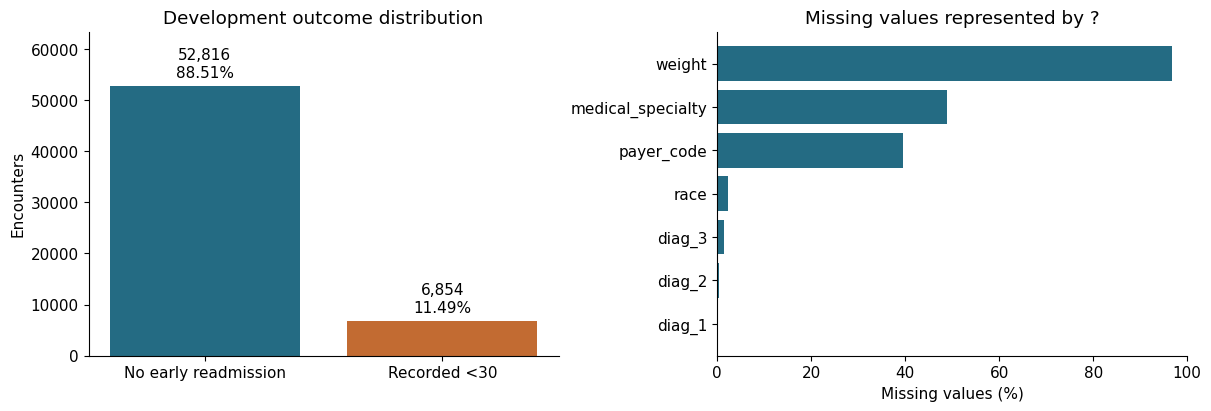

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
bars = axes[0].bar(
    ['No early readmission', 'Recorded <30'],
    class_counts, color=[BLUE, ORANGE],
)
labels = [f'{count:,}\n{count / len(y):.2%}' for count in class_counts]
axes[0].bar_label(bars, labels=labels, padding=4)
axes[0].set(title='Development outcome distribution', ylabel='Encounters')
axes[0].margins(y=.2)
missing_plot = missing_features.iloc[::-1]
axes[1].barh(missing_plot.index, missing_plot.missing_percent, color=BLUE)
axes[1].set(
    title='Missing values represented by ?',
    xlabel='Missing values (%)', xlim=(0, 100),
)
fig.savefig(
    OUT / 'figures/01_class_balance_missingness.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


Early readmission occurs in 11.49% of encounters, so accuracy alone can be misleading. Weight is 96.81% missing. Keep missing medical specialty and payer values as explicit categories.


## Distributions and comparisons by outcome

Plot four key features. Use log count axes for long tails. Boxplots hide extreme points for readability; no rows are deleted.


In [9]:
numeric_summary = numeric_data.describe(percentiles=[.25, .5, .75, .99]).T
numeric_summary['zero_percent'] = numeric_data.eq(0).mean() * 100
display(numeric_summary[['mean', '50%', '75%', '99%', 'max', 'zero_percent']].round(2))


,mean,50%,75%,99%,max,zero_percent
time_in_hospital,4.36,4.0,6.0,13.0,14.0,0.00
num_lab_procedures,42.87,44.0,57.0,84.0,132.0,0.00
num_procedures,1.33,1.0,2.0,6.0,6.0,46.15
num_medications,15.97,15.0,20.0,43.0,79.0,0.00
number_outpatient,0.37,0.0,0.0,5.0,40.0,83.62
number_emergency,0.20,0.0,0.0,3.0,76.0,88.76
number_inpatient,0.64,0.0,1.0,6.0,21.0,66.60
number_diagnoses,7.41,8.0,9.0,9.0,16.0,0.00


### Plot distributions by outcome

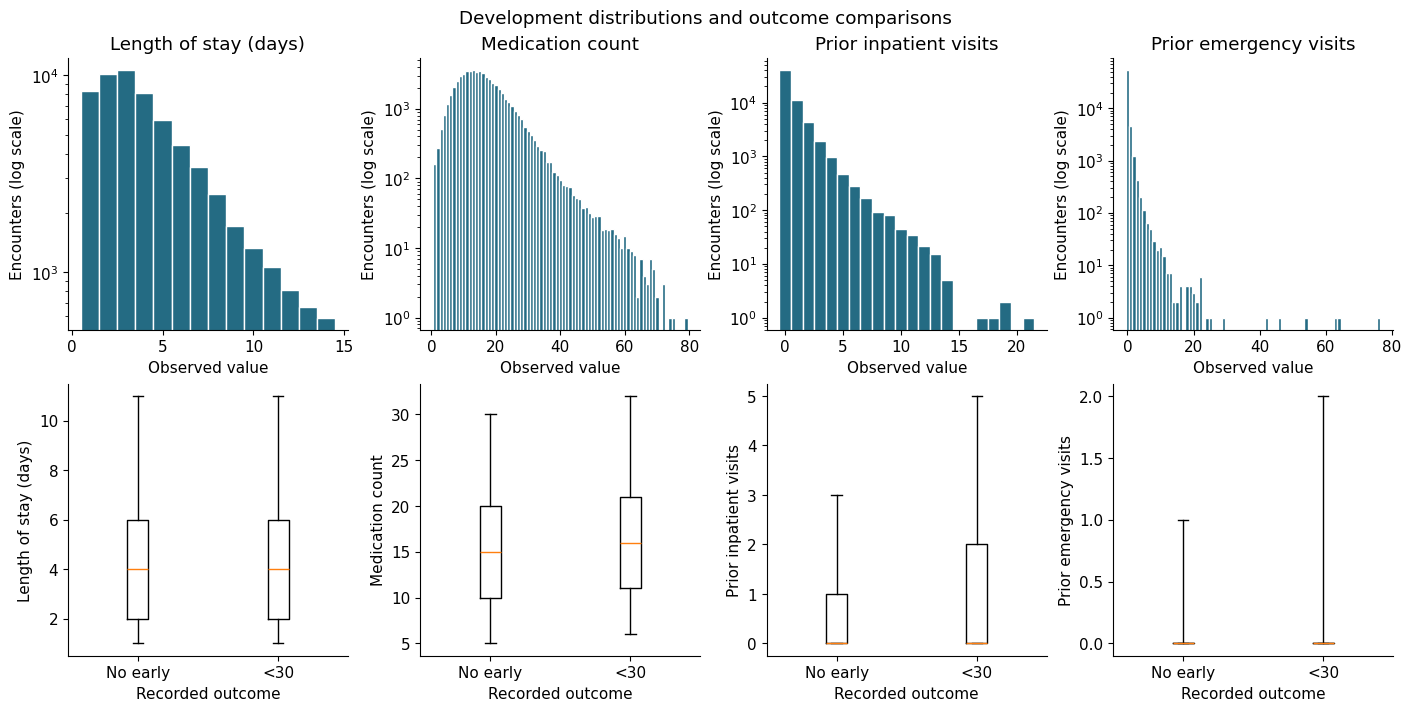

In [10]:
key_features = {
    'time_in_hospital': 'Length of stay (days)',
    'num_medications': 'Medication count',
    'number_inpatient': 'Prior inpatient visits',
    'number_emergency': 'Prior emergency visits',
}
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout='constrained')
for i, (name, label) in enumerate(key_features.items()):
    values = X[name]
    bins = np.arange(values.min() - .5, values.max() + 1.5)
    axes[0, i].hist(values, bins=bins, color=BLUE, edgecolor='white')
    axes[0, i].set(
        title=label, ylabel='Encounters (log scale)',
        xlabel='Observed value', yscale='log',
    )
    axes[1, i].boxplot(
        [X.loc[y.eq(0), name], X.loc[y.eq(1), name]],
        tick_labels=['No early', '<30'],
        whis=(5, 95), showfliers=False,
    )
    axes[1, i].set(xlabel='Recorded outcome', ylabel=label)
fig.suptitle('Development distributions and outcome comparisons')
fig.savefig(
    OUT / 'figures/02_distributions_boxplots.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


Prior visits are mostly zero and have long tails. The early-readmission group has more prior inpatient visits, but the groups overlap.


## Relationships between features

Use a Spearman heatmap to check relationships between numerical features.


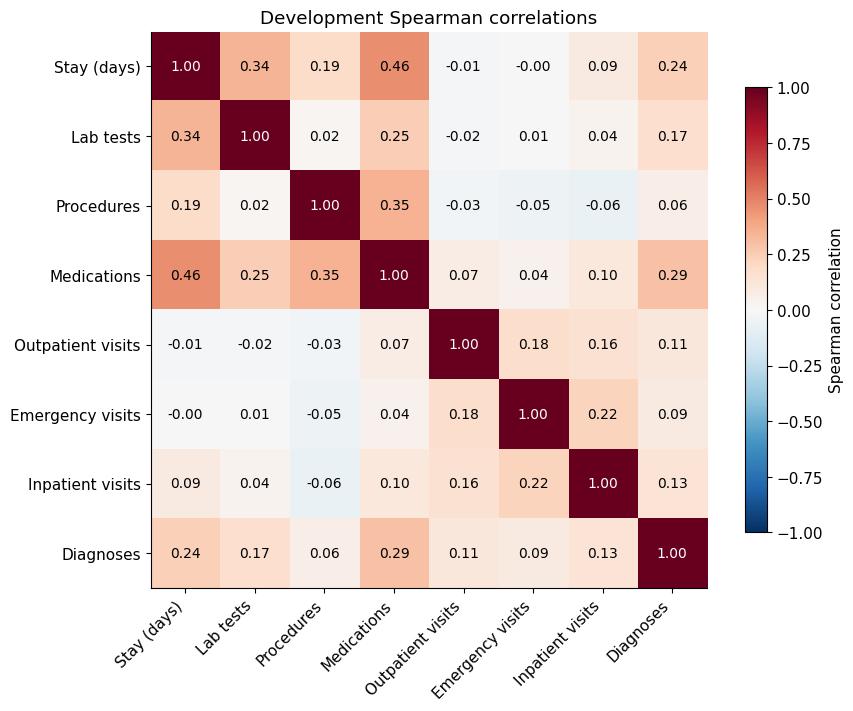

In [11]:
correlations = numeric_data.corr(method='spearman')

short_labels = [
    'Stay (days)', 'Lab tests', 'Procedures', 'Medications',
    'Outpatient visits', 'Emergency visits', 'Inpatient visits', 'Diagnoses',
]
fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
image = ax.imshow(correlations, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(8), short_labels, rotation=45, ha='right')
ax.set_yticks(range(8), short_labels)
for i in range(8):
    for j in range(8):
        value = correlations.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > .65 else 'black', fontsize=10)
ax.set_title('Development Spearman correlations')
fig.colorbar(image, ax=ax, label='Spearman correlation', shrink=.8)
fig.savefig(OUT / 'figures/03_correlations.png', dpi=150, bbox_inches='tight')
plt.show()


The strongest numerical correlation is 0.463 between stay duration and medication count. No pair reaches 0.80.


## Screen outliers


In [12]:
q1 = numeric_data.quantile(.25)
q3 = numeric_data.quantile(.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
iqr_flags = numeric_data.lt(lower) | numeric_data.gt(upper)
outlier_summary = pd.DataFrame({
    'q1': q1, 'q3': q3, 'iqr': iqr, 'lower_fence': lower, 'upper_fence': upper,
    'flagged_encounters': iqr_flags.sum(), 'flagged_percent': iqr_flags.mean() * 100,
})
display(outlier_summary.round(2))
print(f'Encounters flagged in at least one field: {iqr_flags.any(axis=1).sum():,}')


,q1,q3,iqr,lower_fence,upper_fence,flagged_encounters,flagged_percent
time_in_hospital,2.0,6.0,4.0,-4.0,12.0,1256,2.10
num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,74,0.12
num_procedures,0.0,2.0,2.0,-3.0,5.0,2894,4.85
num_medications,10.0,20.0,10.0,-5.0,35.0,1452,2.43
number_outpatient,0.0,0.0,0.0,0.0,0.0,9772,16.38
number_emergency,0.0,0.0,0.0,0.0,0.0,6709,11.24
number_inpatient,0.0,1.0,1.0,-1.5,2.5,4140,6.94
number_diagnoses,6.0,9.0,3.0,1.5,13.5,159,0.27


Encounters flagged in at least one field: 20,162


## Preprocessing: clean the development predictors


In [13]:
def diagnosis_group(value):
    if pd.isna(value):
        return np.nan
    try:
        code = float(value)
    except ValueError:
        return 'Other'  # Includes V and E codes.
    if 250 <= code < 251:
        return 'Diabetes'
    for low, high, extra, label in [
        (390, 460, 785, 'Circulatory'), (460, 520, 786, 'Respiratory'),
        (520, 580, 787, 'Digestive'), (580, 630, 788, 'Genitourinary'),
        (710, 740, -1, 'Musculoskeletal'), (800, 1000, -1, 'Injury'),
        (140, 240, -1, 'Neoplasms'),
    ]:
        if low <= code < high or int(code) == extra:
            return label
    return 'Other'


### Clean predictors

In [14]:
X_clean = X.copy()
categorical_features = [name for name in X_clean if name not in numeric_features]
X_clean[categorical_features] = X_clean[categorical_features].astype('string')

for name in ['diag_1', 'diag_2', 'diag_3']:
    X_clean[name] = X_clean[name].map(diagnosis_group)

# Drop features with over 95% missing values or only one value.
drop_mask = X_clean.isna().mean().gt(.95) | X_clean.nunique(dropna=False).le(1)
dropped_features = X_clean.columns[drop_mask].tolist()
X_clean = X_clean.drop(columns=dropped_features)
categorical_features = [name for name in X_clean if name not in numeric_features]
print('Dropped features:', dropped_features)
print('Retained predictors:', X_clean.shape[1])


Dropped features: ['weight', 'acetohexamide', 'examide', 'citoglipton', 'metformin-rosiglitazone']
Retained predictors: 42


## Independent feature selection with mutual information


In [15]:
mi_inputs = X_clean.apply(lambda column: pd.factorize(column)[0])
mi_scores = mutual_info_classif(mi_inputs, y, discrete_features=True, random_state=SEED)
feature_ranking = pd.DataFrame({
    'feature': X_clean.columns, 'mutual_information': mi_scores,
}).sort_values('mutual_information', ascending=False, kind='stable')
selected_features = feature_ranking.head(20)['feature'].tolist()
feature_ranking['selected'] = feature_ranking.feature.isin(selected_features)
display(feature_ranking.head(20).reset_index(drop=True))


,feature,mutual_information,selected
0,number_inpatient,0.0115,True
1,discharge_disposition_id,0.0058,True
2,number_emergency,0.0024,True
3,medical_specialty,0.0020,True
4,num_medications,0.0019,True
5,time_in_hospital,0.0017,True
6,number_diagnoses,0.0017,True
7,num_lab_procedures,0.0014,True
8,number_outpatient,0.0010,True
9,insulin,0.0008,True


## Standardize numerical features and encode categories


In [16]:
numeric_medians = X_clean[numeric_features].median()
X_filled = X_clean.copy()
X_filled[numeric_features] = X_filled[numeric_features].fillna(numeric_medians)
X_filled[categorical_features] = X_filled[categorical_features].fillna('Missing')
assert not X_filled.isna().any().any()


### Scale and encode features

In [17]:
encoder = OneHotEncoder(
    handle_unknown='infrequent_if_exist', min_frequency=25,
)
preprocessor_all = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categorical', encoder, categorical_features),
], sparse_threshold=1.0)
X_all = preprocessor_all.fit_transform(X_filled)


### Keep the selected features

In [18]:
encoded_names = preprocessor_all.get_feature_names_out()
selected_numeric_names = [f'numeric__{name}' for name in selected_features]
selected_category_prefixes = tuple(
    f'categorical__{name}_' for name in selected_features
)
selected_columns = [
    i for i, name in enumerate(encoded_names)
    if name in selected_numeric_names or name.startswith(selected_category_prefixes)
]
X_selected = X_all[:, selected_columns]
print('All retained features after encoding:', X_all.shape)
print('Top 20 features after encoding:', X_selected.shape)
assert np.isfinite(X_all.data).all()
assert np.isfinite(X_selected.data).all()


All retained features after encoding: (59670, 216)
Top 20 features after encoding: (59670, 147)


In [19]:
scaler = preprocessor_all.named_transformers_['numeric']
scaled_numeric = scaler.transform(X_filled[numeric_features])
scaling_check = pd.DataFrame({
    'mean_after': scaled_numeric.mean(axis=0),
    'std_after': scaled_numeric.std(axis=0),
}, index=numeric_features)
display(scaling_check.round(4))
np.testing.assert_allclose(scaling_check['mean_after'], 0, atol=1e-10)
np.testing.assert_allclose(scaling_check['std_after'], 1, atol=1e-10)


,mean_after,std_after
time_in_hospital,0.0,1.0
num_lab_procedures,0.0,1.0
num_procedures,0.0,1.0
num_medications,0.0,1.0
number_outpatient,0.0,1.0
number_emergency,-0.0,1.0
number_inpatient,0.0,1.0
number_diagnoses,-0.0,1.0


## Dimensionality reduction with PCA


In [20]:
pca = PCA(n_components=.95, svd_solver='full')
X_pca = pca.fit_transform(X_all.toarray())
cumulative_variance = pca.explained_variance_ratio_.cumsum()
pca_variance = pd.DataFrame({
    'component': np.arange(1, pca.n_components_ + 1),
    'variance_ratio': pca.explained_variance_ratio_,
    'cumulative_variance': cumulative_variance,
})
print(f'PCA dimensions: {X_all.shape[1]} -> {X_pca.shape[1]}')
print(f'Retained variance: {cumulative_variance[-1]:.2%}')
assert cumulative_variance[-1] >= .95
assert np.isfinite(X_pca).all()


PCA dimensions: 216 -> 65
Retained variance: 95.11%


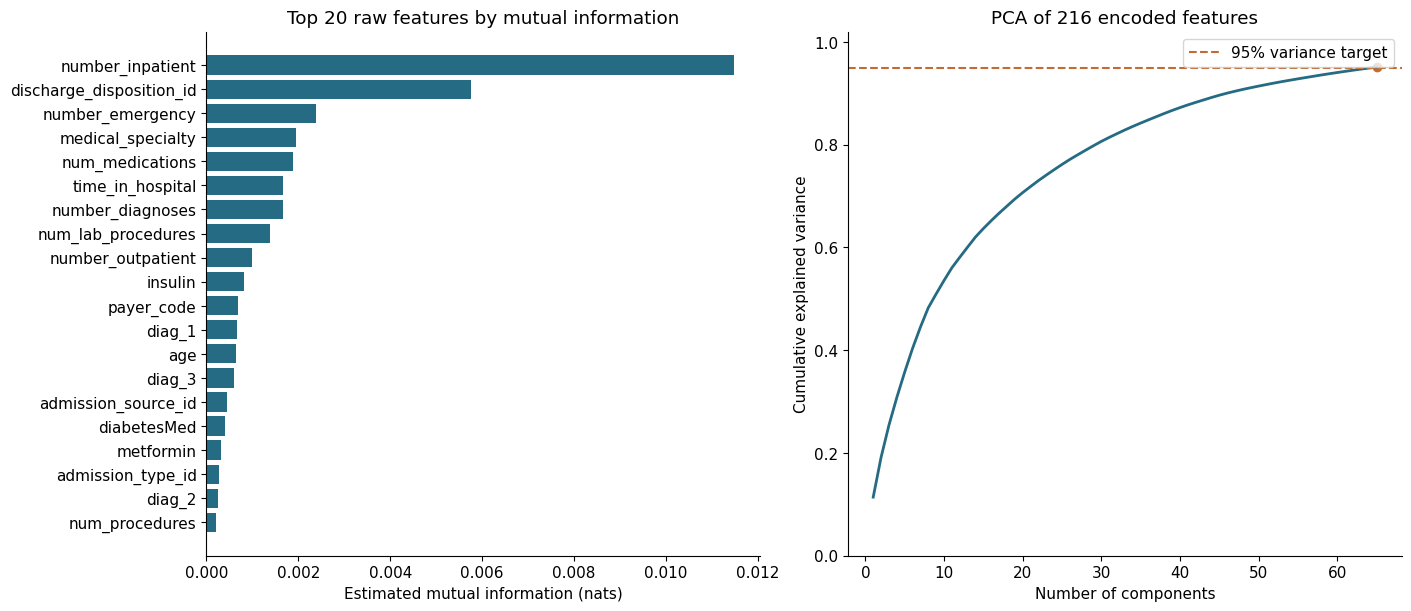

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
top_features = feature_ranking.head(20).iloc[::-1]
axes[0].barh(top_features.feature, top_features.mutual_information, color=BLUE)
axes[0].set(
    title='Top 20 raw features by mutual information',
    xlabel='Estimated mutual information (nats)',
)
axes[1].plot(
    pca_variance.component, pca_variance.cumulative_variance,
    color=BLUE, linewidth=2,
)
axes[1].axhline(.95, color=ORANGE, linestyle='--', label='95% variance target')
axes[1].scatter([pca.n_components_], [cumulative_variance[-1]], color=ORANGE)
axes[1].set(
    title=f'PCA of {X_all.shape[1]} encoded features',
    xlabel='Number of components',
    ylabel='Cumulative explained variance', ylim=(0, 1.02),
)
axes[1].legend()
fig.savefig(
    OUT / 'figures/04_feature_selection_pca.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


## Save EDA tables


In [22]:
missingness.to_csv(OUT / 'tables/missingness.csv')
numeric_summary.to_csv(OUT / 'tables/numeric_summary.csv')
outlier_summary.to_csv(OUT / 'tables/outlier_summary.csv')
feature_ranking.to_csv(OUT / 'tables/feature_selection.csv', index=False)
pca_variance.to_csv(OUT / 'tables/pca_variance.csv', index=False)
print('Saved five EDA tables to notebooks/outputs/tables/')


Saved five EDA tables to notebooks/outputs/tables/


## Save training data

Save encoded development features and the target. Keep IDs for patient-based splits; exclude them from model inputs. Refit preprocessing within each training fold for cross-validation.


In [23]:
training_data = pd.DataFrame(
    X_all.toarray(), columns=encoded_names,
)
training_data.insert(0, 'encounter_id', dev['encounter_id'].to_numpy())
training_data.insert(1, 'patient_nbr', dev['patient_nbr'].to_numpy())
training_data['target'] = y.to_numpy()
training_data.to_csv(ROOT / 'data/processed/training.csv', index=False)
print(
    f'Saved {len(training_data):,} training encounters and '
    f'{X_all.shape[1]} encoded features to data/processed/training.csv'
)


Saved 59,670 training encounters and 216 encoded features to data/processed/training.csv


## References

- [UCI dataset](https://doi.org/10.24432/C5230J).
- scikit-learn: [preprocessing](https://scikit-learn.org/1.7/modules/preprocessing.html), [mutual information](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_selection.mutual_info_classif.html), and [PCA](https://scikit-learn.org/1.7/modules/generated/sklearn.decomposition.PCA.html).
